# 基于 PE 的分析师锚定效应偏差（CAF_EP）

**行为金融因子 —— 分析师预测锚定效应**

$$
\text{CAF_EP}_{i,t} = \frac{\text{FEP}_{i,t} - \text{IFEP}_t}{\text{IFEP}_t}
$$

其中，$\text{FEP}_{i,t}$ 为分析师在时间 $t$ 对股票 $i$ 的 PE 预测值所对应的盈利预测（即 PE 的倒数）：

$$
\text{FEP}_{i,t} = \frac{1}{\text{FPE}_{i,t}}
$$

各变量定义如下：

* $\text{FPE}_{i,t}$ 为分析师在时间 $t$ 对股票 $i$ 的 PE 指标的预测值；
* $\text{FEP}_{i,t}$ 为股票 $i$ 在时间 $t$ 的预期盈利水平（PE 的倒数），用于衡量估值水平的高低；
* $\text{IFEP}_t$ 为股票 $i$ 所属行业中所有成分股的 $\text{FPE}_{i,t}$ 的中位数（即行业中位数 PE 的倒数）。

## 因子说明

**锚定效应**指人们在做出判断时，会将最初接触到的信息（即“锚点”）作为参考依据，并在其基础上进行调整，但调整往往不充分，从而导致判断偏差。在分析师预测场景中，锚定效应表现为：分析师会以公司所在行业的估值水平（行业中位数 PE）作为定价的“锚点”。当某只股票的估值指标超出行业中位数时（即 $\text{CAF_EP}_{i,t} > 0$），分析师会倾向于做出**悲观预测**，将预测值向行业中位数靠拢；反之，当估值低于行业中位数时（即 $\text{CAF_EP}_{i,t} < 0$），分析师会倾向于做出**乐观预测**。财报公布后，实际财务指标将与分析师预测形成反向修正：被悲观预测的公司，其实际财务指标将高于预测值，股价表现更优；被乐观预测的公司，其实际财务指标将低于预测值，股价表现更差。因此，该因子可用于预测未来股价的走势方向。

数据：PE分析师预测值、行业分类数据、PE

## 有权限

In [1]:
# import rqdatac

# try:
#     test = rqdatac.consensus.get_comp_indicators(
#         order_book_ids=["000001.XSHE"],
#         start_date="2025-01-01",
#         end_date="2025-01-10",
#         fields=["comp_con_pe_ftm"],
#     )
#     print(test.head())
# except Exception as error:
#     print(type(error).__name__)
#     print(error)

In [2]:
# import numpy as np
# import pandas as pd
# import rqdatac

# from rqdatac import (
#     all_instruments,
#     get_trading_dates,
#     get_instrument_industry,
# )


# def _get_consensus_fpe_wide(
#     order_book_ids,
#     dates,
#     fpe_field="comp_con_pe_ftm",
#     report_range=3,
#     batch_size=500,
# ):
#     """下载并整理为：日期 × 股票 的一致预期 PE 宽表。"""
#     parts = []

#     for start in range(0, len(order_book_ids), batch_size):
#         batch = order_book_ids[start:start + batch_size]

#         # 新版 rqdatac 支持 report_range；
#         # 旧版接口不支持时，自动降级为默认查询方式。
#         try:
#             raw = rqdatac.consensus.get_comp_indicators(
#                 order_book_ids=batch,
#                 start_date=dates[0],
#                 end_date=dates[-1],
#                 fields=[fpe_field],
#                 report_range=report_range,
#             )
#         except TypeError as error:
#             if "report_range" not in str(error):
#                 raise

#             raw = rqdatac.consensus.get_comp_indicators(
#                 order_book_ids=batch,
#                 start_date=dates[0],
#                 end_date=dates[-1],
#                 fields=[fpe_field],
#             )

#         if raw is None or raw.empty:
#             continue

#         temp = raw.reset_index()

#         if "order_book_id" not in temp.columns or "date" not in temp.columns:
#             raise ValueError(
#                 "一致预期数据返回格式异常：未找到 order_book_id 或 date 字段。"
#             )

#         temp["date"] = pd.to_datetime(temp["date"])
#         temp = temp[["date", "order_book_id", fpe_field]]
#         parts.append(temp)

#     if not parts:
#         raise RuntimeError(
#             "未取得一致预期 PE 数据。请确认账户已开通一致预期数据权限，"
#             "且 comp_con_pe_ftm 字段可用。"
#         )

#     fpe_long = pd.concat(parts, ignore_index=True)
#     fpe_long = fpe_long.drop_duplicates(
#         subset=["date", "order_book_id"],
#         keep="last",
#     )

#     fpe_wide = fpe_long.pivot(
#         index="date",
#         columns="order_book_id",
#         values=fpe_field,
#     )

#     # 负 PE、零 PE 没有正常的预期估值含义
#     fpe_wide = fpe_wide.where(fpe_wide > 0)

#     # 仅使用过去已经出现的预测值向前填充
#     fpe_wide = (
#         fpe_wide.reindex(index=dates, columns=order_book_ids)
#         .ffill()
#     )

#     return fpe_wide

# def _get_industry_code(
#     order_book_ids,
#     asof_date,
#     industry_source="citics_2019",
#     industry_level=1,
#     batch_size=500,
# ):
#     """获取指定日期的股票行业代码。"""
#     parts = []
#     industry_col = {
#         1: "first_industry_code",
#         2: "second_industry_code",
#         3: "third_industry_code",
#     }[industry_level]

#     for start in range(0, len(order_book_ids), batch_size):
#         batch = order_book_ids[start:start + batch_size]

#         raw = get_instrument_industry(
#             order_book_ids=batch,
#             source=industry_source,
#             level=industry_level,
#             date=asof_date,
#         )

#         if raw is None or raw.empty:
#             continue

#         parts.append(raw[industry_col])

#     if not parts:
#         return pd.Series(index=order_book_ids, dtype=object)

#     return (
#         pd.concat(parts)
#         .loc[lambda x: ~x.index.duplicated(keep="last")]
#         .reindex(order_book_ids)
#     )


# def calculate_caf_ep_daily(
#     start_date,
#     end_date,
#     candidate_ids=None,
#     industry_universe_ids=None,
#     industry_source="citics_2019",
#     industry_level=1,
#     industry_refresh="M",
#     min_industry_stocks=5,
#     initial_lookback_days=370,
#     batch_size=500,
# ):
#     """
#     基于 PE 的分析师锚定效应偏差（CAF_EP）

#     输出：
#         index  : [date, order_book_id]
#         column : CAF_EP

#     参数：
#         candidate_ids         输出因子股票池；None 为全 A 股。
#         industry_universe_ids 计算行业 PE 中位数所用股票池；None 为全 A 股。
#         industry_refresh      行业分类更新频率：'M'（默认）、'Q' 或 'D'。
#                               'M' 在每月首个交易日更新，兼顾时点正确性与效率。
#     """
#     if industry_level not in (1, 2, 3):
#         raise ValueError("industry_level 仅支持 1、2、3。")

#     if industry_refresh not in ("M", "Q", "D"):
#         raise ValueError("industry_refresh 仅支持 'M'、'Q'、'D'。")

#     if candidate_ids is None:
#         candidate_ids = (
#             all_instruments("CS")["order_book_id"]
#             .dropna()
#             .drop_duplicates()
#             .tolist()
#         )
#     else:
#         candidate_ids = list(dict.fromkeys(candidate_ids))

#     if industry_universe_ids is None:
#         industry_universe_ids = (
#             all_instruments("CS")["order_book_id"]
#             .dropna()
#             .drop_duplicates()
#             .tolist()
#         )
#     else:
#         industry_universe_ids = list(dict.fromkeys(industry_universe_ids))

#     # 保证待输出的股票也位于其行业中位数的计算范围内
#     calculation_ids = list(
#         dict.fromkeys(industry_universe_ids + candidate_ids)
#     )

#     start_date = pd.Timestamp(start_date)
#     end_date = pd.Timestamp(end_date)

#     all_dates = pd.DatetimeIndex(
#         get_trading_dates(
#             start_date=start_date - pd.Timedelta(days=initial_lookback_days),
#             end_date=end_date,
#         )
#     )
#     target_dates = all_dates[
#         (all_dates >= start_date) & (all_dates <= end_date)
#     ]

#     if len(target_dates) == 0:
#         raise ValueError("所选区间内没有交易日。")

#     # 1. 获取每日一致预期 FPE，并仅以前值填充
#     fpe_wide_all = _get_consensus_fpe_wide(
#         order_book_ids=calculation_ids,
#         dates=all_dates,
#         fpe_field="comp_con_pe_ftm",
#         report_range=3,
#         batch_size=batch_size,
#     )
#     fpe_wide = fpe_wide_all.reindex(target_dates)

#     # 2. 生成行业分类更新时间点
#     if industry_refresh == "D":
#         refresh_mask = np.ones(len(target_dates), dtype=bool)
#     else:
#         periods = target_dates.to_period(industry_refresh)
#         refresh_mask = ~periods.duplicated()

#     refresh_locs = np.flatnonzero(refresh_mask)
#     factor_wide = pd.DataFrame(
#         index=target_dates,
#         columns=candidate_ids,
#         dtype=float,
#     )

#     # 3. 每个行业分类有效区间内，计算行业 FPE 中位数和 CAF_EP
#     for pos, start_loc in enumerate(refresh_locs):
#         end_loc = (
#             refresh_locs[pos + 1]
#             if pos + 1 < len(refresh_locs)
#             else len(target_dates)
#         )
#         block_dates = target_dates[start_loc:end_loc]
#         industry_date = block_dates[0]

#         industry_code = _get_industry_code(
#             order_book_ids=calculation_ids,
#             asof_date=industry_date,
#             industry_source=industry_source,
#             industry_level=industry_level,
#             batch_size=batch_size,
#         )

#         valid_ids = industry_code[industry_code.notna()].index.tolist()
#         if not valid_ids:
#             continue

#         fpe_block = fpe_wide.loc[block_dates, valid_ids]
#         group_key = industry_code.reindex(valid_ids)

#         # 行业内每个交易日的 FPE 中位数与有效股票数
#         industry_median_fpe = (
#             fpe_block.T.groupby(group_key, sort=False).median().T
#         )
#         industry_count = (
#             fpe_block.T.groupby(group_key, sort=False).count().T
#         )

#         # 行业内有效预期 PE 股票过少时，不产生因子值
#         industry_median_fpe = industry_median_fpe.where(
#             industry_count >= min_industry_stocks
#         )

#         # 将每只股票所在行业的中位数映射回个股
#         reference_fpe = industry_median_fpe.reindex(
#             columns=group_key.values
#         )
#         reference_fpe.columns = valid_ids

#         # CAF_EP = 行业 FPE 中位数 / 个股 FPE - 1
#         block_factor = (
#             reference_fpe.reindex(columns=candidate_ids)
#             .div(fpe_wide.loc[block_dates, candidate_ids])
#             - 1.0
#         )

#         factor_wide.loc[block_dates, candidate_ids] = block_factor

#     result = factor_wide.stack(dropna=True).rename("CAF_EP").to_frame()
#     result.index = result.index.set_names(["date", "order_book_id"])

#     return result

In [3]:
# caf_ep = calculate_caf_ep_daily(
#     start_date="2020-01-01",
#     end_date="2025-12-31",
#     candidate_ids=None,
#     industry_universe_ids=None,
#     industry_source="citics_2019",
#     industry_level=1,
#     industry_refresh="M",
#     min_industry_stocks=5,
#     batch_size=500,
# )

# caf_ep.head()

## 无权限

本地数据符合构建 CAF_EP 的要求，已按给定公式完成日频因子构建。

- 一致预期 PE：`comp_con_pe_ftm`，日频覆盖 2010-01-04 至 2026-09-03。
- 行业分类：包含 `first_industry_code`，月频覆盖至 2026-09-01。
- 本地行业数据仅含一级行业，因此本次采用 `industry_level=1`。
- 原描述提及的“实际 PE”不参与所给代码与公式计算；本地的预测 PE 与行业分类已足够。

结果（2020-01-02 至 2025-12-31）：

- 5,188,061 条记录，1,455 个交易日，4,389 只股票。
- 无空值、无无穷值、无重复 `date + order_book_id`。
- 每日可计算股票数中位数为 3,685。
- CAF_EP 最小值 `-0.999836`，符合理论下界 `-1`；最大值 `241.753`。该因子不存在理论上界，极端正值来自非常接近零的正预测 PE，属公式的正常数值特征。用于回测前建议按日做 1%/99% 缩尾。

文件：

- [日频 CAF_EP 因子](</data/ricequant/factor_output/caf_ep/caf_ep_daily.parquet>)
- [每日覆盖与数值摘要](</data/ricequant/factor_output/caf_ep/caf_ep_daily_summary.csv>)
- [可复现构建脚本](</data/ricequant/build_caf_ep_factor.py>)


In [4]:
from pathlib import Path

import numpy as np
import pandas as pd


FPE_FIELD = "comp_con_pe_ftm"
INDUSTRY_FIELD = "first_industry_code"


def _get_dated_files(directory):
    """
    读取 YYYY-MM-DD.parquet 文件并返回：
    {Timestamp: Path}
    """
    directory = Path(directory)
    result = {}

    for file_path in directory.glob("*.parquet"):
        try:
            result[pd.Timestamp(file_path.stem)] = file_path
        except ValueError:
            continue

    if not result:
        raise FileNotFoundError(
            "目录中未找到日期命名的 parquet 文件：{}".format(
                directory
            )
        )

    return result


def _read_positive_fpe(file_path, calculation_ids=None):
    """
    读取单日预测 PE。

    非正预测 PE 无经济含义，按缺失值处理；
    后续会以前一有效值向前填充。
    """
    data = pd.read_parquet(
        file_path,
        columns=["order_book_id", FPE_FIELD],
    )

    required_columns = {"order_book_id", FPE_FIELD}
    missing_columns = required_columns - set(data.columns)

    if missing_columns:
        raise ValueError(
            "{} 缺少字段：{}".format(
                file_path.name,
                sorted(missing_columns),
            )
        )

    data[FPE_FIELD] = pd.to_numeric(
        data[FPE_FIELD],
        errors="coerce",
    )

    data = data.loc[
        data[FPE_FIELD] > 0,
        ["order_book_id", FPE_FIELD],
    ]

    if calculation_ids is not None:
        data = data[
            data["order_book_id"].isin(calculation_ids)
        ]

    return (
        data
        .drop_duplicates(
            subset=["order_book_id"],
            keep="last",
        )
        .set_index("order_book_id")[FPE_FIELD]
    )


def _read_industry(file_path):
    """
    读取单个行业分类快照。

    本地数据中使用一级中信行业：
    first_industry_code
    """
    data = pd.read_parquet(
        file_path,
        columns=["order_book_id", INDUSTRY_FIELD],
    )

    required_columns = {
        "order_book_id",
        INDUSTRY_FIELD,
    }

    missing_columns = required_columns - set(data.columns)

    if missing_columns:
        raise ValueError(
            "{} 缺少字段：{}".format(
                file_path.name,
                sorted(missing_columns),
            )
        )

    return (
        data
        .dropna(subset=["order_book_id"])
        .drop_duplicates(
            subset=["order_book_id"],
            keep="last",
        )
        .set_index("order_book_id")[INDUSTRY_FIELD]
    )


def _normalize_ids(ids):
    if ids is None:
        return None

    if isinstance(ids, str):
        return {ids}

    return set(dict.fromkeys(ids))


def calculate_caf_ep_daily_from_local(
    start_date,
    end_date,
    candidate_ids=None,
    industry_universe_ids=None,
    data_dir="data",
    min_industry_stocks=5,
    initial_lookback_days=370,
):
    """
    基于本地数据构建日频 CAF_EP 因子。

    Parameters
    ----------
    start_date, end_date : str
        输出因子的起止日期。

    candidate_ids : list[str] or str, optional
        因子输出股票池。None 表示所有可计算股票。

    industry_universe_ids : list[str] or str, optional
        计算行业预测 PE 中位数的股票池。
        None 表示全部可取得有效预测 PE 的股票。

    data_dir : str
        本地数据目录，默认 data。

    min_industry_stocks : int
        行业内当日有效预测 PE 股票数下限。
        少于该数量的行业不输出因子值。

    initial_lookback_days : int
        向前读取预测 PE 的自然日窗口，用于前向填充。

    Returns
    -------
    pd.DataFrame
        MultiIndex: [date, order_book_id]
        Column: CAF_EP
    """
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    if start_date > end_date:
        raise ValueError("start_date 不能晚于 end_date。")

    if min_industry_stocks < 1:
        raise ValueError(
            "min_industry_stocks 至少应为 1。"
        )

    data_dir = Path(data_dir)

    fpe_dir = (
        data_dir
        / "get_comp_indicators"
        / FPE_FIELD
    )

    industry_dir = (
        data_dir
        / "get_instrument_industry_monthly"
    )

    fpe_files = _get_dated_files(fpe_dir)
    industry_files = _get_dated_files(industry_dir)

    fpe_dates = pd.DatetimeIndex(
        sorted(fpe_files.keys())
    )

    industry_dates = pd.DatetimeIndex(
        sorted(industry_files.keys())
    )

    candidate_set = _normalize_ids(candidate_ids)
    industry_universe_set = _normalize_ids(
        industry_universe_ids
    )

    # 确保待输出股票也纳入行业中位数的计算范围
    if (
        candidate_set is None
        and industry_universe_set is None
    ):
        calculation_ids = None
    else:
        calculation_ids = (
            (candidate_set or set())
            | (industry_universe_set or set())
        )

    lookback_start = (
        start_date
        - pd.Timedelta(days=initial_lookback_days)
    )

    process_dates = fpe_dates[
        (fpe_dates >= lookback_start)
        & (fpe_dates <= end_date)
    ]

    target_dates = process_dates[
        process_dates >= start_date
    ]

    if len(target_dates) == 0:
        raise ValueError(
            "所选区间内没有可用的预测 PE 交易日。"
        )

    # 保存每只股票最近一次有效的正预测 PE。
    # 对应原始代码中：FPE > 0 后再 ffill。
    last_valid_fpe = {}

    current_industry = pd.Series(dtype=object)
    current_industry_position = None

    result_parts = []

    for date in process_dates:
        # 更新当日有效预测 PE
        daily_fpe = _read_positive_fpe(
            file_path=fpe_files[date],
            calculation_ids=calculation_ids,
        )

        if not daily_fpe.empty:
            last_valid_fpe.update(
                daily_fpe.to_dict()
            )

        # lookback 期只用于建立 FPE 前值，不输出因子
        if date < start_date or not last_valid_fpe:
            continue

        # 使用当前日期之前最近一期的月度行业分类
        industry_position = (
            industry_dates.searchsorted(
                date,
                side="right",
            )
            - 1
        )

        if industry_position < 0:
            continue

        if industry_position != current_industry_position:
            current_industry_position = industry_position

            current_industry = _read_industry(
                industry_files[
                    industry_dates[industry_position]
                ]
            )

        # 当日可用的、前向填充后的 FPE
        fpe = pd.Series(
            last_valid_fpe,
            name="FPE",
            dtype=float,
        )

        frame = pd.DataFrame({
            "FPE": fpe,
            "industry": current_industry.reindex(
                fpe.index
            ),
        })

        frame = frame.dropna(
            subset=["FPE", "industry"]
        )

        # 计算行业预测 PE 中位数时使用的股票池
        if industry_universe_set is None:
            median_universe = frame
        else:
            median_universe = frame.loc[
                frame.index.isin(industry_universe_set)
            ]

        if median_universe.empty:
            continue

        industry_median_fpe = (
            median_universe
            .groupby("industry")["FPE"]
            .median()
        )

        industry_fpe_count = (
            median_universe
            .groupby("industry")["FPE"]
            .count()
        )

        eligible_industries = industry_fpe_count[
            industry_fpe_count >= min_industry_stocks
        ].index

        if len(eligible_industries) == 0:
            continue

        frame = frame.loc[
            frame["industry"].isin(eligible_industries)
        ].copy()

        frame["industry_median_fpe"] = (
            frame["industry"].map(industry_median_fpe)
        )

        # CAF_EP
        # = (1 / 个股 FPE - 1 / 行业 FPE 中位数)
        #   / (1 / 行业 FPE 中位数)
        # = 行业 FPE 中位数 / 个股 FPE - 1
        frame["CAF_EP"] = (
            frame["industry_median_fpe"]
            / frame["FPE"]
            - 1.0
        )

        # 输出股票池筛选
        if candidate_set is not None:
            frame = frame.loc[
                frame.index.isin(candidate_set)
            ]

        if frame.empty:
            continue

        result_part = (
            frame[["CAF_EP"]]
            .reset_index()
            .rename(
                columns={"index": "order_book_id"}
            )
        )

        result_part.insert(0, "date", date)

        result_parts.append(result_part)

    if not result_parts:
        raise RuntimeError(
            "未生成 CAF_EP 因子，请检查数据路径、"
            "行业分类覆盖与 min_industry_stocks 设置。"
        )

    result = pd.concat(
        result_parts,
        ignore_index=True,
    )

    result = (
        result
        .sort_values(["date", "order_book_id"])
        .set_index(["date", "order_book_id"])
    )

    result.index = result.index.set_names(
        ["date", "order_book_id"]
    )

    return result

In [5]:
# 全市场日频 CAF_EP
caf_ep = calculate_caf_ep_daily_from_local(
    start_date="2020-01-01",
    end_date="2025-12-31",
    candidate_ids=None,
    industry_universe_ids=None,
    data_dir="data",
    min_industry_stocks=5,
    initial_lookback_days=370,
)

caf_ep.head()
# 按照当前公式，CAF_EP > 0 实际表示个股预测 PE 低于行业预测 PE 中位数。若你希望使用“个股预测 PE 高于行业中位数时因子为正”的符号定义，可在计算后反向：
# caf_ep["CAF_EP"] = -caf_ep["CAF_EP"]

CAF_EP
date       order_book_id          
2020-01-02 000001.XSHE   -0.398053
           000002.XSHE    0.002024
           000006.XSHE    0.233829
           000008.XSHE    0.089046
           000009.XSHE   -0.314511

In [8]:
caf_ep_df = (
    caf_ep["CAF_EP"]
    .unstack("order_book_id")
    .sort_index()
)

caf_ep_df.index = pd.to_datetime(caf_ep_df.index)
caf_ep_df.columns.name = "order_book_id"

from rqfactor.notebook import factor_analysis

result_caf_ep = factor_analysis(
    f=caf_ep_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=False,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)
result_caf_ep.show()

Loading BokehJS ...

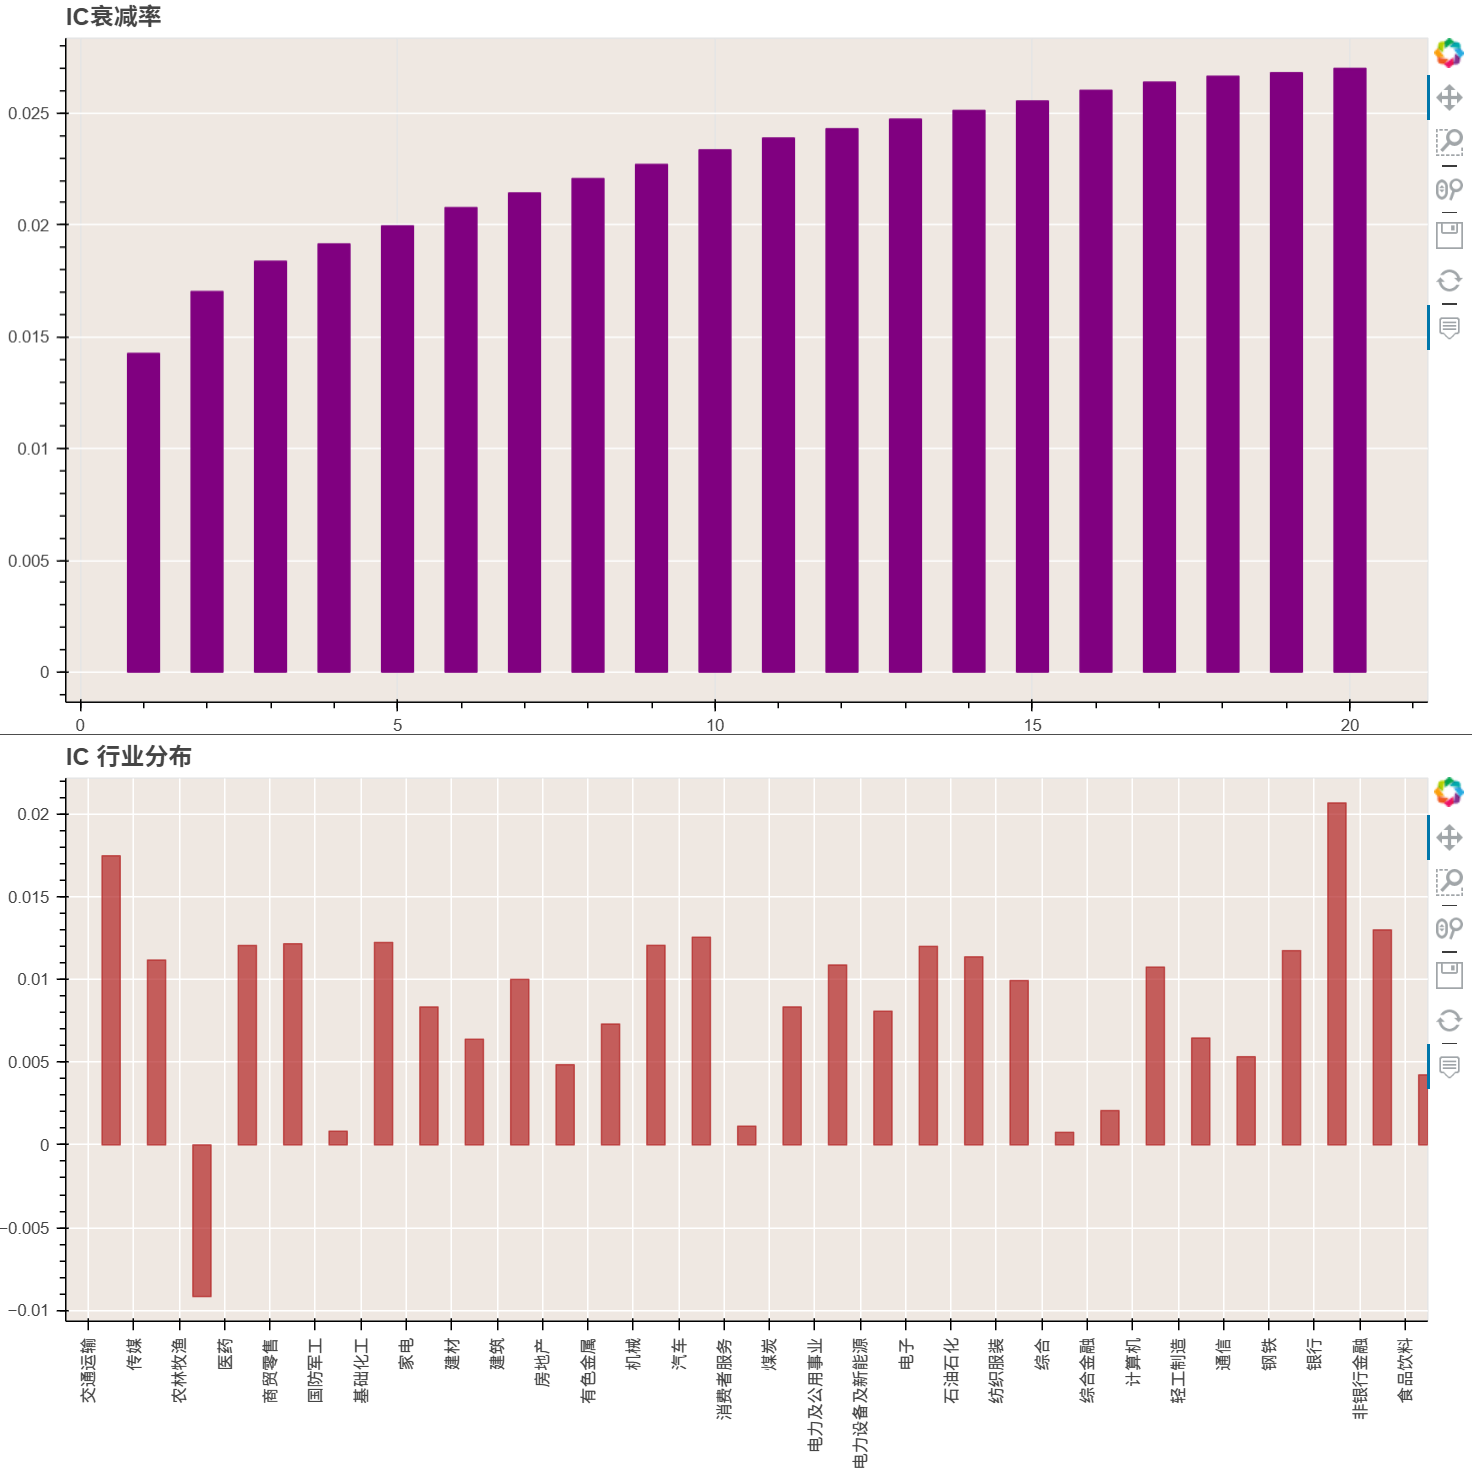

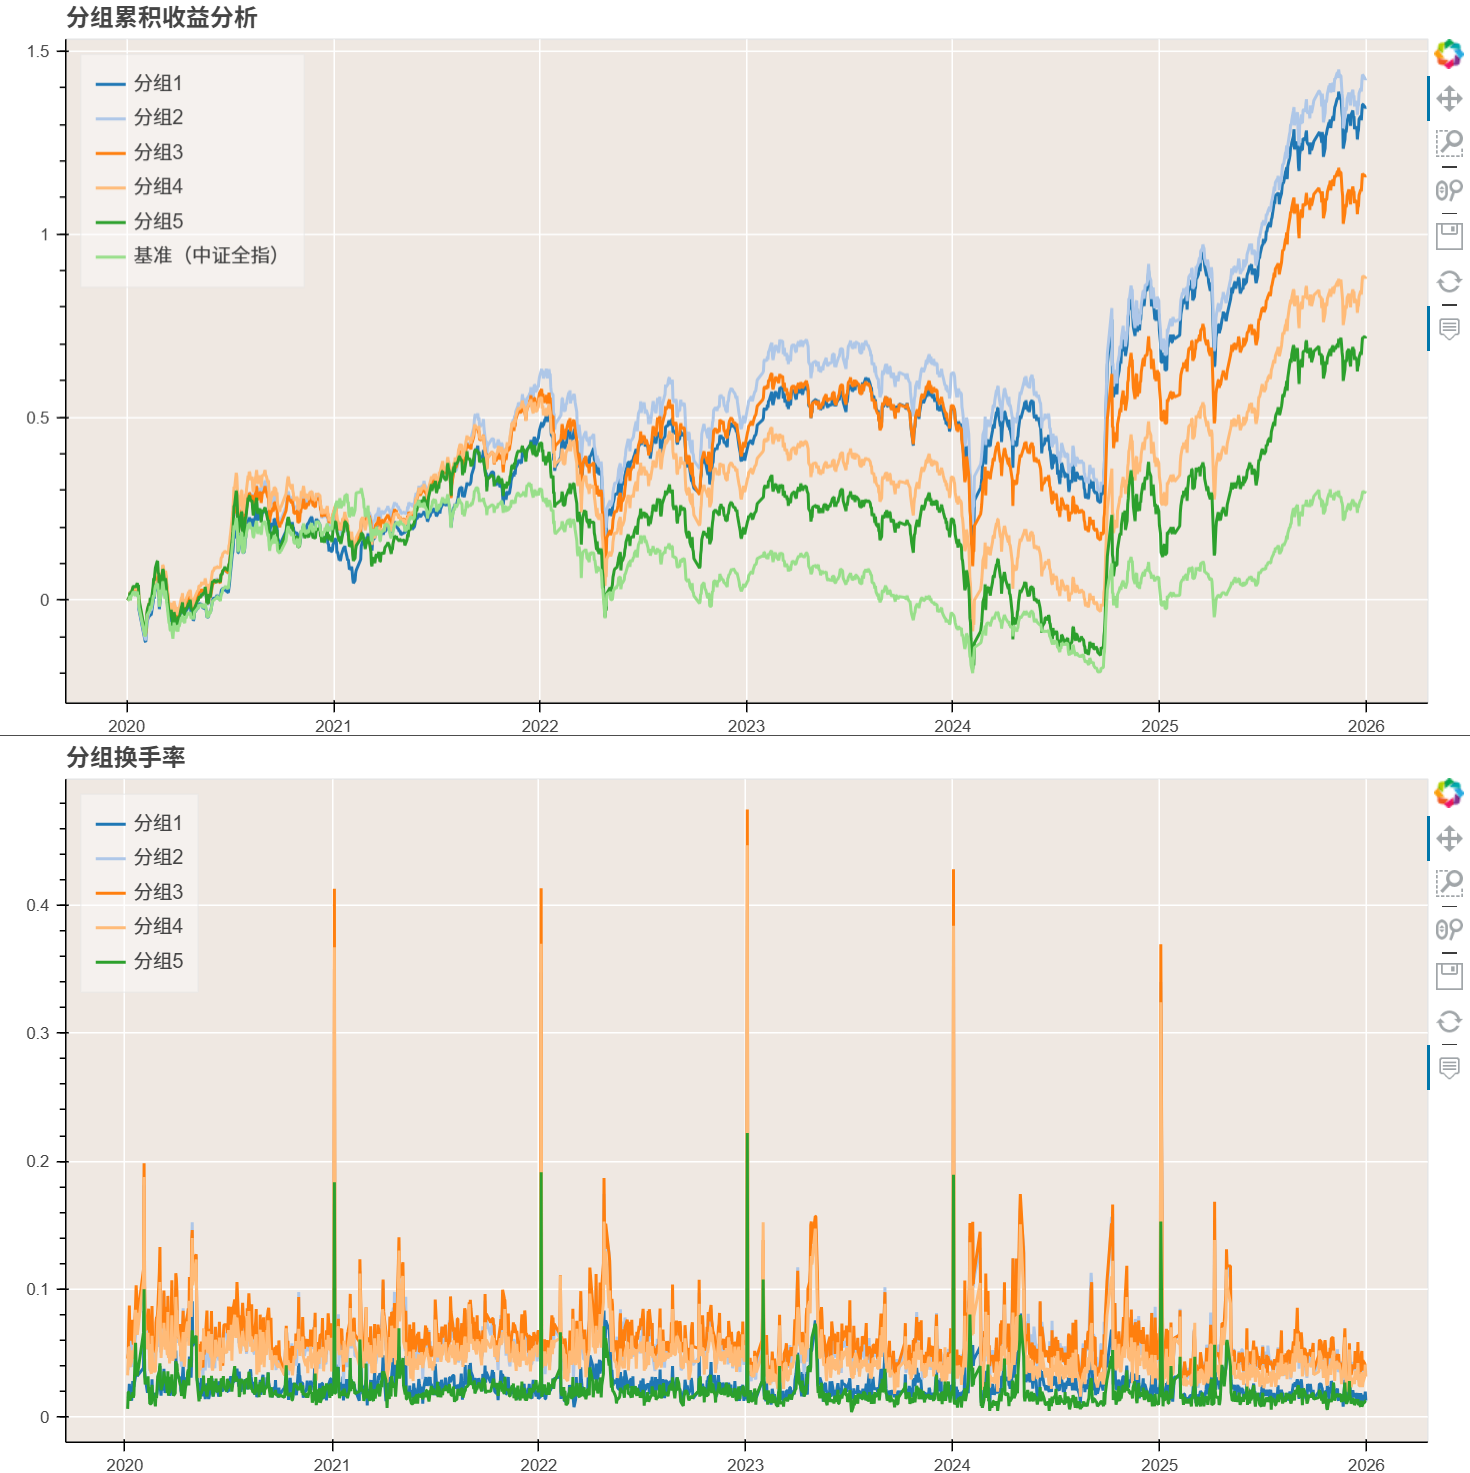

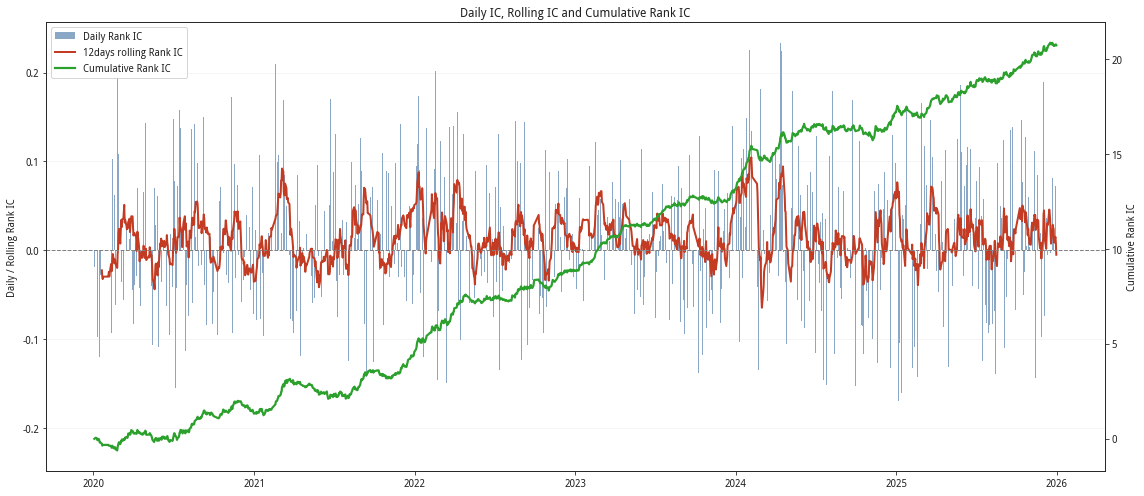

In [9]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_caf_ep.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()